In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

**Environment Setup**

In [2]:
!pip install pandas numpy scikit-learn seaborn matplotlib biopython


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.9 MB/s eta 0:00:00:00:01


**Downloading The Dataset**

In [4]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/kp-meropenem-tsv/kp_amr_dataset.tsv
/kaggle/input/kp-meropenem-ncbi-tsv/kp_meropenem_ncbi.tsv
/kaggle/input/klebsiella-pneumoniae-meropenem-ncbi/kp_meropenem_ncbi.tsv


In [6]:
import pandas as pd

# Load the dataset from the correct folder
df = pd.read_csv("/kaggle/input/klebsiella-pneumoniae-meropenem-ncbi/kp_meropenem_ncbi.tsv", sep="\t")

# Preview first few rows
df.head()

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,#Organism group,Strain,Isolate identifiers,Serovar,Isolate,Create date,Location,Isolation source,Isolation type,Food origin,SNP cluster,Min-same,Min-diff,BioSample,Assembly,AMR genotypes,Computed types
0,Klebsiella pneumoniae,UHKPC28,1134709401451 Klebsiella pneumoniae UHKPC27 UH...,NaN,PDT000015887.2,2013-07-01T23:02:21Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02141969,GCA_000417105.1,"aac(6')-Ib=COMPLETE,blaKPC-2=COMPLETE,blaOXA=M...",NaN
1,Klebsiella pneumoniae,UHKPC47,1134709401465 Klebsiella pneumoniae UHKPC45 UH...,NaN,PDT000015889.2,2013-07-01T23:02:37Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02142017,GCA_000417125.1,"aac(6')-Ib=COMPLETE,aadA2=COMPLETE,blaKPC-2=CO...",NaN
2,Klebsiella pneumoniae,UHKPC23,1134709401443 Klebsiella pneumoniae UHKPC22 UH...,NaN,PDT000015890.2,2013-05-23T17:06:26Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02141978,GCA_000401195.1,"aac(6')-Ib=COMPLETE,aadA2=COMPLETE,blaKPC-2=CO...",NaN
3,Klebsiella pneumoniae,UHKPC69,1134709401479 Klebsiella pneumoniae UHKPC69 UH...,NaN,PDT000015891.2,2013-07-01T23:10:57Z,NaN,NaN,NaN,NaN,PDS000239878.1,NaN,NaN,SAMN02142026,GCA_000417305.1,"aac(3)-IVa=COMPLETE,aadA2=COMPLETE,aph(4)-Ia=C...",NaN
4,Klebsiella pneumoniae,UHKPC77,1134709401481 Klebsiella pneumoniae UHKPC77 UH...,NaN,PDT000015892.2,2013-07-01T23:11:14Z,NaN,NaN,NaN,NaN,PDS000239878.1,NaN,NaN,SAMN02142027,GCA_000417325.1,"aac(3)-IVa=COMPLETE,aadA2=PARTIAL_END_OF_CONTI...",NaN


In [7]:
df.shape
df.columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1195 entries, 0 to 1194
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   #Organism group      1195 non-null   object 
 1   Strain               734 non-null    object 
 2   Isolate identifiers  1195 non-null   object 
 3   Serovar              0 non-null      float64
 4   Isolate              1195 non-null   object 
 5   Create date          1195 non-null   object 
 6   Location             969 non-null    object 
 7   Isolation source     936 non-null    object 
 8   Isolation type       1093 non-null   object 
 9   Food origin          19 non-null     object 
 10  SNP cluster          708 non-null    object 
 11  Min-same             624 non-null    float64
 12  Min-diff             60 non-null     float64
 13  BioSample            1195 non-null   object 
 14  Assembly             929 non-null    object 
 15  AMR genotypes        1194 non-null   o

**Basic Cleaning**

In [8]:
# Inspect columns and missing data
df.info()

# Rename messy column headers (remove '#', spaces)
df.columns = df.columns.str.strip().str.replace('#', '').str.replace(' ', '_')

# Drop columns that are fully empty
df = df.dropna(axis=1, how='all')

# Preview cleaned columns
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1195 entries, 0 to 1194
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   #Organism group      1195 non-null   object 
 1   Strain               734 non-null    object 
 2   Isolate identifiers  1195 non-null   object 
 3   Serovar              0 non-null      float64
 4   Isolate              1195 non-null   object 
 5   Create date          1195 non-null   object 
 6   Location             969 non-null    object 
 7   Isolation source     936 non-null    object 
 8   Isolation type       1093 non-null   object 
 9   Food origin          19 non-null     object 
 10  SNP cluster          708 non-null    object 
 11  Min-same             624 non-null    float64
 12  Min-diff             60 non-null     float64
 13  BioSample            1195 non-null   object 
 14  Assembly             929 non-null    object 
 15  AMR genotypes        1194 non-null   o

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,Organism_group,Strain,Isolate_identifiers,Isolate,Create_date,Location,Isolation_source,Isolation_type,Food_origin,SNP_cluster,Min-same,Min-diff,BioSample,Assembly,AMR_genotypes
0,Klebsiella pneumoniae,UHKPC28,1134709401451 Klebsiella pneumoniae UHKPC27 UH...,PDT000015887.2,2013-07-01T23:02:21Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02141969,GCA_000417105.1,"aac(6')-Ib=COMPLETE,blaKPC-2=COMPLETE,blaOXA=M..."
1,Klebsiella pneumoniae,UHKPC47,1134709401465 Klebsiella pneumoniae UHKPC45 UH...,PDT000015889.2,2013-07-01T23:02:37Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02142017,GCA_000417125.1,"aac(6')-Ib=COMPLETE,aadA2=COMPLETE,blaKPC-2=CO..."
2,Klebsiella pneumoniae,UHKPC23,1134709401443 Klebsiella pneumoniae UHKPC22 UH...,PDT000015890.2,2013-05-23T17:06:26Z,NaN,NaN,NaN,NaN,PDS000045272.43,NaN,NaN,SAMN02141978,GCA_000401195.1,"aac(6')-Ib=COMPLETE,aadA2=COMPLETE,blaKPC-2=CO..."


**Step 2: Check unique values**

In [9]:
print(df['Organism_group'].unique())
print(df['Isolation_source'].unique())
print(df['Location'].dropna().unique()[:10])


['Klebsiella pneumoniae']
[nan 'stool' 'blood' 'urine' 'endotrachael' 'respiratory' 'sputum' 'CSF'
 'drainage' 'aspirate' 'rectal' 'TISSUE, abdomen' 'bone tissue, toe' 'BAL'
 'Peritoneal' 'Tissue' 'Wound fluid' 'Bile (fluid)' 'Wound - abdominal'
 'wound' 'PERITONEAL FLUID' 'BLOOD CULTURE' 'Pleural tissue'
 'Wound - deep sinus' 'ulcer' 'trachael aspirate' 'abdominal'
 'SURVEILLANCE' 'EXUDATE' 'Gastric Contents' 'Peritoneal Fluid'
 'tracheal aspirate' 'abscess' 'Fluid_Peritoneal' 'Blood_whole'
 'Fluid_Pleural' 'Fluid_Synovial' 'Fluid_Ascitic' 'body fluid' 'bile'
 'bronchial washings' 'bronchial alveolar lavage' 'Rectal'
 'Broncholaveolar lavage' 'Catheter urine' 'Biliary drain fluid'
 'Abdominal ascites fluid' 'Urine, cytoscopy' 'feces' 'swab'
 'Catheter tip' 'Pus swab' 'cerebrospinal fluid' 'throat'
 'cerebrospinal fluid (CSF)' 'general (wound, abcess, Etc.)'
 'meropenem treated soil' 'Abdominal pus' 'Swab from Pharynx'
 'Swab from tracheostomic tube' 'Enviromental' 'Surveillance'
 'not

**Step 3: Count number of isolates per country or year**

<Axes: title={'center': 'Isolate Counts per Year'}, xlabel='Year'>

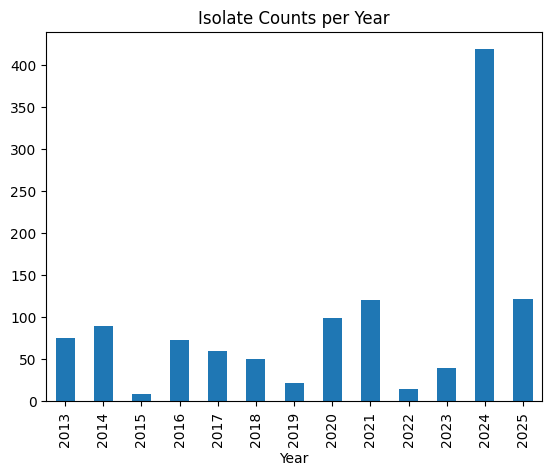

In [10]:
# Extract year from Create date
df['Year'] = pd.to_datetime(df['Create_date'], errors='coerce').dt.year

# Count per year
year_counts = df['Year'].value_counts().sort_index()
year_counts.plot(kind='bar', title='Isolate Counts per Year')


<Axes: title={'center': 'Top 10 Sample Origins'}, xlabel='Location'>

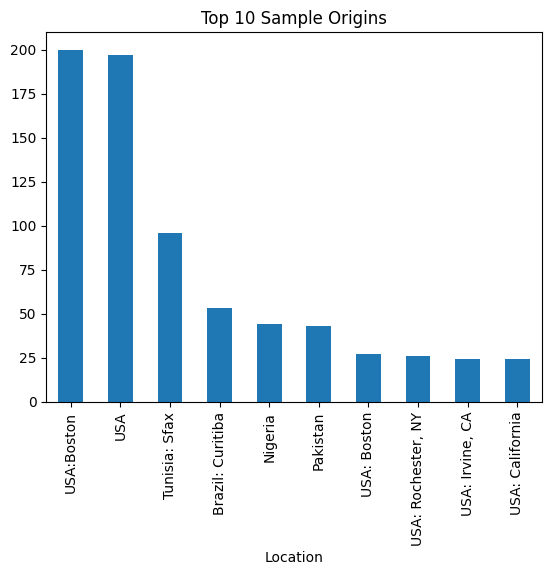

In [11]:
country_counts = df['Location'].value_counts().head(10)
country_counts.plot(kind='bar', title='Top 10 Sample Origins')


****Step 4: Check for AMR-related columns****

In [13]:
df.columns[df.columns.str.contains('resist|antibiotic|gene|amr', case=False)]


Index(['AMR_genotypes'], dtype='object')

**🧩 Step 5: Create a Binary Resistance Label**

In [14]:
# Fill missing values
df['AMR_genotypes'] = df['AMR_genotypes'].fillna('')

# Define carbapenemase genes associated with Meropenem resistance
carbapenem_genes = [
    'blaKPC', 'blaNDM', 'blaOXA', 'blaVIM', 'blaIMP',
    'blaGES', 'blaIMI', 'blaSME', 'blaBIC', 'blaNMC'
]

# Create binary resistance column
df['Meropenem_Resistant'] = df['AMR_genotypes'].apply(
    lambda x: 1 if any(g.lower() in x.lower() for g in carbapenem_genes) else 0
)

# View resistance counts
df['Meropenem_Resistant'].value_counts()

Meropenem_Resistant
1    780
0    415
Name: count, dtype: int64

**📊 Step 6: Visualize Resistance Distribution**

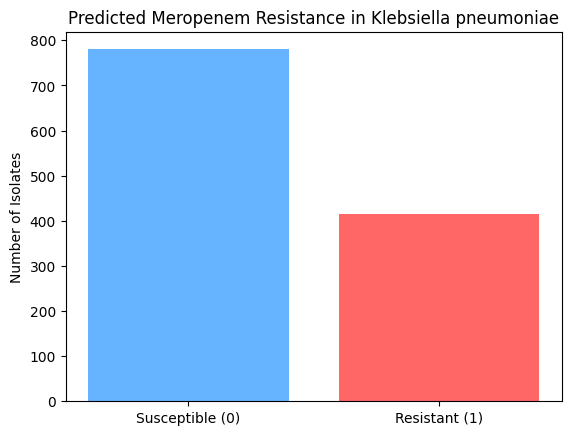

In [15]:
import matplotlib.pyplot as plt

counts = df['Meropenem_Resistant'].value_counts()
plt.bar(['Susceptible (0)', 'Resistant (1)'], counts, color=['#66b3ff','#ff6666'])
plt.title('Predicted Meropenem Resistance in Klebsiella pneumoniae')
plt.ylabel('Number of Isolates')
plt.show()

**Step 7: Prepare Features for Modeling**

In [16]:
from sklearn.feature_extraction.text import CountVectorizer

# Vectorize AMR genes into numerical features
vectorizer = CountVectorizer(token_pattern=r'[^,; ]+')
X_genes = vectorizer.fit_transform(df['AMR_genotypes'])
X_genes = pd.DataFrame(X_genes.toarray(), columns=vectorizer.get_feature_names_out())

# Add metadata (optional)
X = pd.concat([X_genes, pd.get_dummies(df[['Year','Location']], dummy_na=True)], axis=1)
y = df['Meropenem_Resistant']

print(f"Feature matrix shape: {X.shape}")
print(f"Label distribution:\n{y.value_counts()}")

Feature matrix shape: (1195, 510)
Label distribution:
Meropenem_Resistant
1    780
0    415
Name: count, dtype: int64


**Step 8: Train and Evaluate a Model**

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        91
           1       0.95      0.97      0.96       148

    accuracy                           0.95       239
   macro avg       0.95      0.94      0.95       239
weighted avg       0.95      0.95      0.95       239



**🔍 Step 9: Identify Key Resistance Genes**

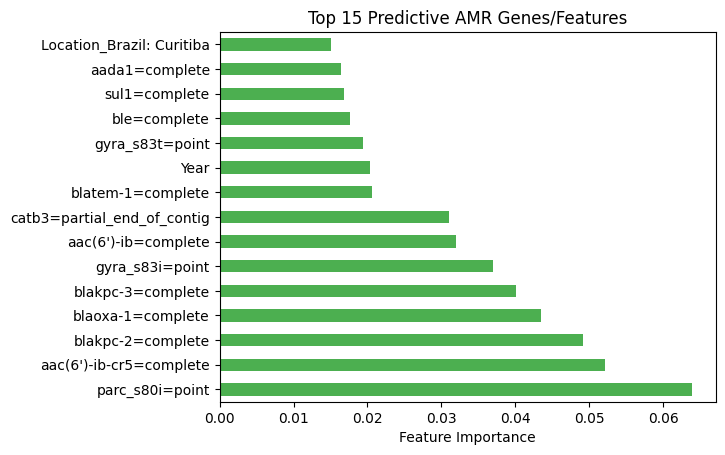

In [18]:
feat_importances = pd.Series(model.feature_importances_, index=X.columns)
top_feats = feat_importances.sort_values(ascending=False).head(15)
top_feats.plot(kind='barh', color='#4CAF50', title='Top 15 Predictive AMR Genes/Features')
plt.xlabel('Feature Importance')
plt.show()


**Adding  SHAP explainability (per-isolate feature impact)**

In [19]:
!pip install shap -q

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure we still have your trained objects in memory:
# X, y, X_train, X_test, y_train, y_test, model
print(type(model), X_test.shape)

<class 'sklearn.ensemble._forest.RandomForestClassifier'> (239, 510)


**A2) Compute SHAP values (focus on the “resistant (1)” class)**

In [20]:
# SHAP can be slow; use a manageable sample of the test set
X_test_sample = X_test.sample(n=min(300, len(X_test)), random_state=42)

# TreeExplainer works well with RandomForest
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_sample)

# For binary classifiers, shap_values is a list [class0, class1]
sv_pos = shap_values[1]
sv_pos.shape


(239, 510)

**A3) Global explanations (which features matter most overall)**

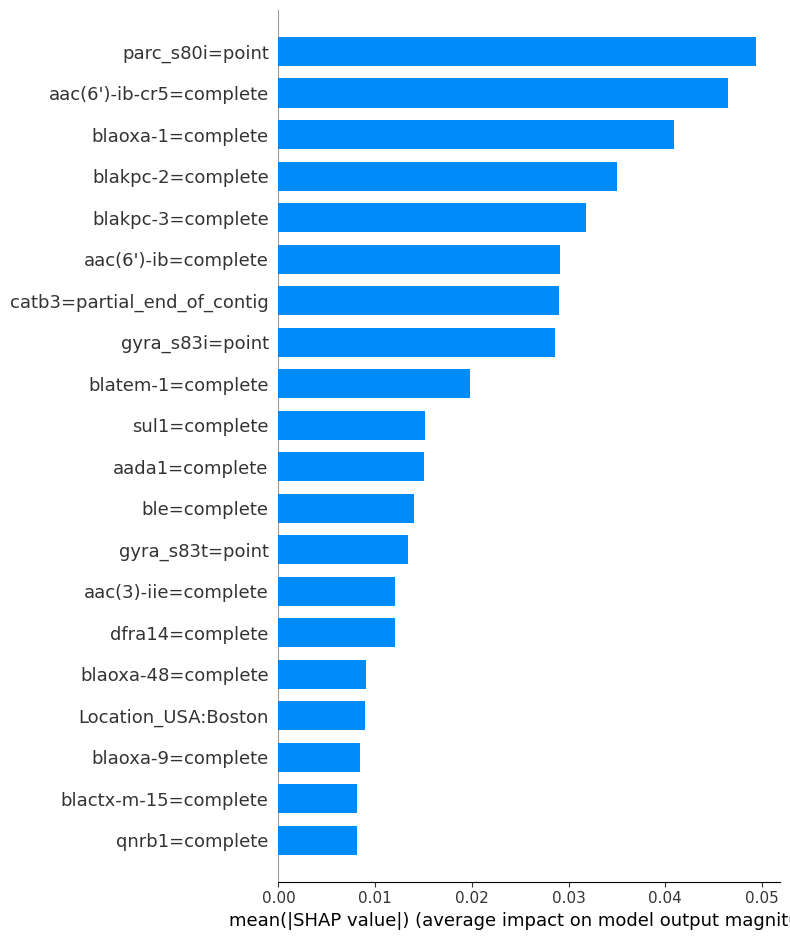

In [21]:
# 1) Bar summary: average absolute impact per feature
shap.summary_plot(sv_pos, X_test_sample, feature_names=X.columns, plot_type="bar", max_display=20)


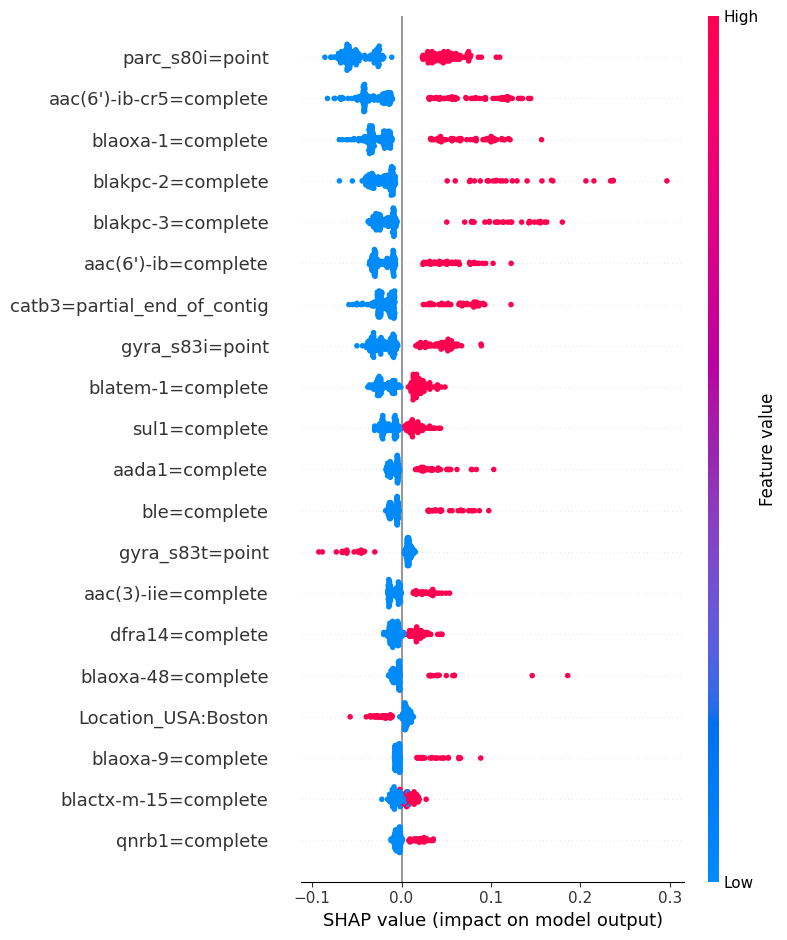

In [22]:
# 2) Beeswarm: direction + magnitude per sample (red = pushes toward resistant, blue = toward susceptible)
shap.summary_plot(sv_pos, X_test_sample, feature_names=X.columns, max_display=20)


**A4) Optional: Explain a single isolate**

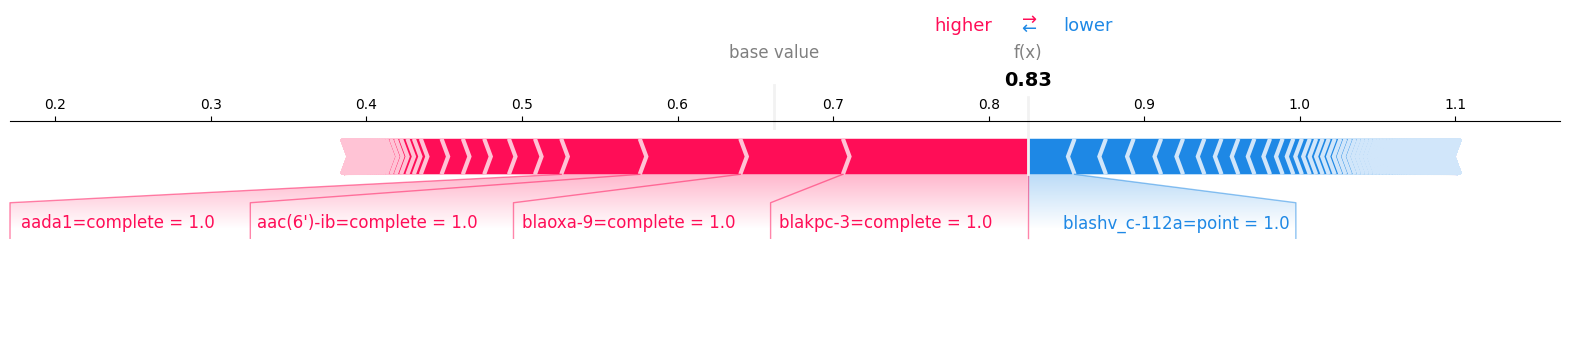

In [23]:
# Pick one resistant prediction to inspect (or any index from X_test_sample.index)
idx = X_test_sample.index[0]
shap.force_plot(explainer.expected_value[1], sv_pos[X_test_sample.index.get_loc(idx)], 
                X_test_sample.loc[idx], matplotlib=True)


**Step B — Country-Level Heatmap of Meropenem Resistance.**

**Step B: Visualize Resistance by Country**

In [51]:
# Ensure Location is treated as string and handle NaNs safely
df['Location'] = df['Location'].astype(str)

# Extract only the country part (before ':' or ',' or '.')
df['Country'] = (
    df['Location']
    .str.split(':|,|\\.|;')   # split on colon, comma, dot, or semicolon
    .str[0]
    .str.strip()
    .replace({'nan': np.nan, '': np.nan})
)

# Normalize known country variations
df['Country'] = df['Country'].replace({
    'USA': 'United States',
    'USA Boston': 'United States',
    'USA Boston ': 'United States',
    'USA Boston.': 'United States',
    'USA Rochester NY': 'United States',
    'USA California': 'United States',
    'Tunisia Sfax': 'Tunisia',
    'Brazil Curitiba': 'Brazil',
    'Nigeria': 'Nigeria',
    'Pakistan': 'Pakistan'
})

# Check the unique values after cleaning
print("✅ Unique Country Names Found:")
print(df['Country'].dropna().unique())


✅ Unique Country Names Found:
['United States' 'Afghanistan' 'Honduras' 'Germany' 'Pakistan' 'Sweden'
 'Russia' 'South Africa' 'Israel' 'Brazil' 'China' 'Kazakhstan' 'Ukraine'
 'South Korea' 'Kenya' 'Thailand' 'Philippines' 'Italy' 'Jordan' 'Guam'
 'Peru' 'Turkey' 'Portugal' 'Ireland' 'Canada' 'Tunisia' 'Nigeria'
 'United Kingdom']


**B2) Compute resistance frequency by country**

In [52]:
# Count total isolates and resistant isolates per country
country_stats = (
    df.groupby('Country')['Meropenem_Resistant']
      .agg(['count', 'sum'])
      .rename(columns={'count': 'Total_Isolates', 'sum': 'Resistant_Isolates'})
)

# Add resistance rate (%)
country_stats['Resistance_Rate_%'] = (
    country_stats['Resistant_Isolates'] / country_stats['Total_Isolates'] * 100
).round(2)

country_stats = country_stats.sort_values('Resistance_Rate_%', ascending=False)
country_stats.head(10)


,Total_Isolates,Resistant_Isolates,Resistance_Rate_%
Country,,,
Tunisia,96,96,100.00
Honduras,2,2,100.00
Sweden,2,2,100.00
Italy,3,3,100.00
Portugal,6,6,100.00
Ireland,20,20,100.00
Philippines,1,1,100.00
Ukraine,1,1,100.00
United Kingdom,3,3,100.00


**B3) Plot heatmap of resistance rates**

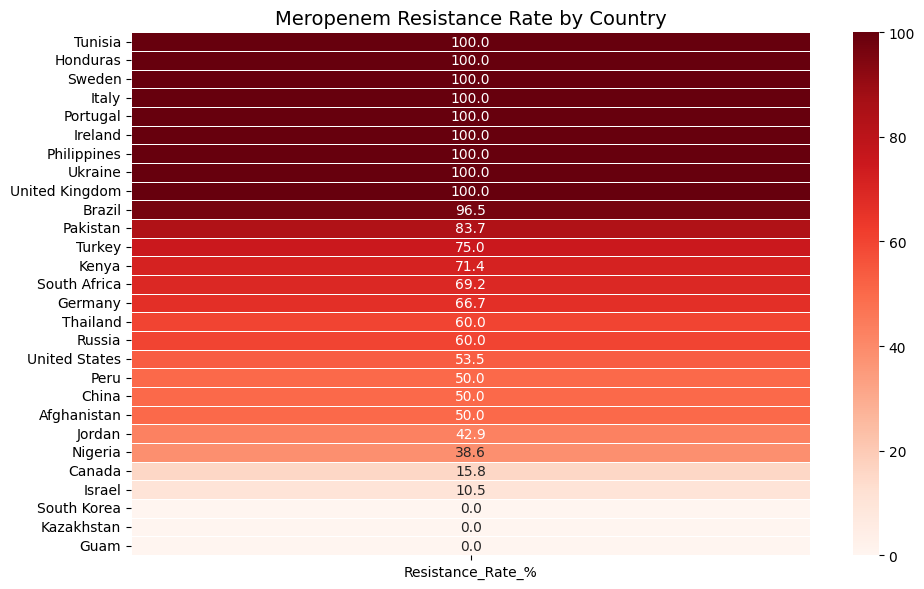

In [53]:
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(
    country_stats[['Resistance_Rate_%']],
    annot=True, cmap='Reds', linewidths=0.5, fmt=".1f"
)
plt.title('Meropenem Resistance Rate by Country', fontsize=14)
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()


**Step C – Temporal Trend Analysis**

**C1. Prepare yearly data and compute rolling mean**

In [54]:
# --- Aggregate resistance per year ---
yearly_stats = (
    df.groupby('Year')['Meropenem_Resistant']
      .agg(['count', 'sum'])
      .rename(columns={'count': 'Total_Isolates', 'sum': 'Resistant_Isolates'})
)

# --- Calculate yearly resistance rate (%) ---
yearly_stats['Resistance_Rate_%'] = (
    yearly_stats['Resistant_Isolates'] / yearly_stats['Total_Isolates'] * 100
)

# --- Apply a 3-year rolling average for smooth trend ---
yearly_stats['Rolling_Mean_%'] = (
    yearly_stats['Resistance_Rate_%'].rolling(window=3, min_periods=1).mean()
)

# Preview
yearly_stats.tail()


,Total_Isolates,Resistant_Isolates,Resistance_Rate_%,Rolling_Mean_%
Year,,,,
2021,121,65,53.719008,62.182430
2022,15,11,73.333333,63.899602
2023,40,24,60.000000,62.350781
2024,418,280,66.985646,66.772993
2025,122,94,77.049180,68.011609


******C2. Plot smooth resistance trend (with optional isolate-count overlay)**

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


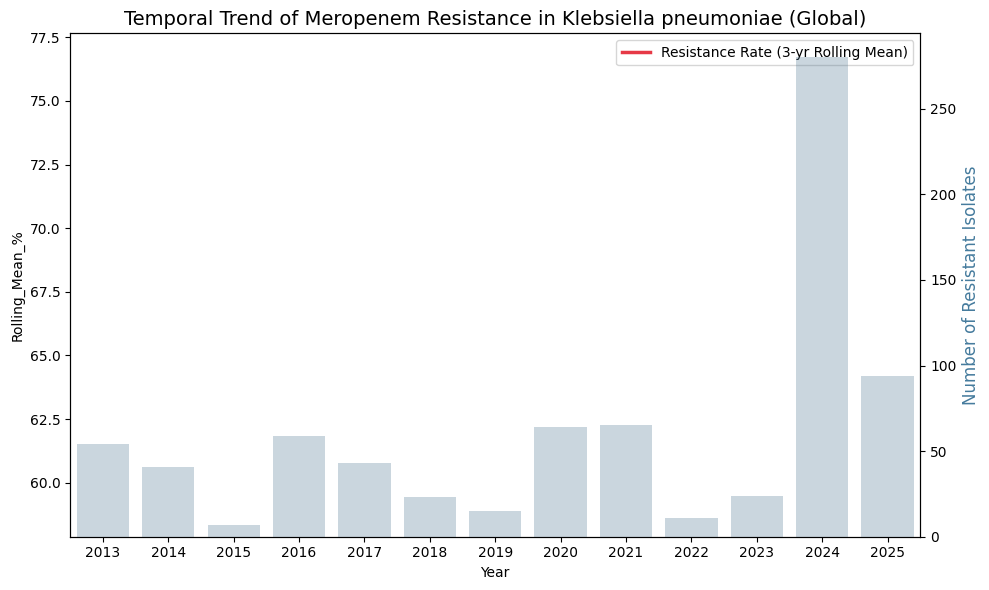

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

# Resistance trend (rolling mean)
sns.lineplot(
    data=yearly_stats, 
    x=yearly_stats.index, 
    y='Rolling_Mean_%',
    label='Resistance Rate (3-yr Rolling Mean)',
    linewidth=2.5, 
    color='#e63946'
)

# Optional overlay: resistant isolate counts
ax2 = plt.twinx()
sns.barplot(
    x=yearly_stats.index, 
    y='Resistant_Isolates', 
    data=yearly_stats,
    alpha=0.3, 
    color='#457b9d',
    ax=ax2,
    label='Resistant Isolate Count'
)

# Styling
plt.title('Temporal Trend of Meropenem Resistance in Klebsiella pneumoniae (Global)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Resistance Rate (%)', fontsize=12, color='#e63946')
ax2.set_ylabel('Number of Resistant Isolates', fontsize=12, color='#457b9d')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Step D – Country-Specific Temporal Trends**

**D1. Group by Year + Country**

In [56]:
# --- Group by Year and Country ---
country_year = (
    df.groupby(['Country', 'Year'])['Meropenem_Resistant']
      .agg(['count', 'sum'])
      .rename(columns={'count': 'Total_Isolates', 'sum': 'Resistant_Isolates'})
      .reset_index()
)

# --- Calculate yearly resistance rate (%) per country ---
country_year['Resistance_Rate_%'] = (
    country_year['Resistant_Isolates'] / country_year['Total_Isolates'] * 100
)

# --- Apply 3-year rolling mean per country ---
country_year['Rolling_Mean_%'] = (
    country_year
    .groupby('Country')['Resistance_Rate_%']
    .transform(lambda x: x.rolling(window=3, min_periods=1).mean())
)

# Check top entries
country_year.head()


,Country,Year,Total_Isolates,Resistant_Isolates,Resistance_Rate_%,Rolling_Mean_%
0,Afghanistan,2016,1,1,100.000000,100.000000
1,Afghanistan,2021,1,0,0.000000,50.000000
2,Brazil,2020,5,4,80.000000,80.000000
3,Brazil,2023,1,1,100.000000,90.000000
4,Brazil,2025,52,51,98.076923,92.692308


**D2. Plot Multi-Country Trend (Top 5 or Custom)**

use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
When grouping wi

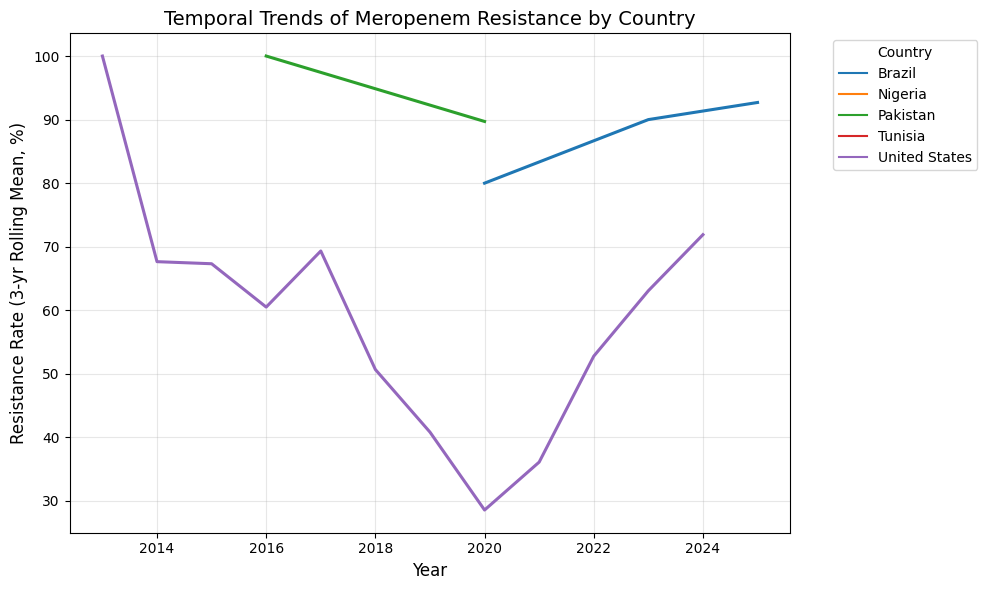

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Select top countries by isolate count ---
top_countries = (
    df['Country'].value_counts().head(5).index.tolist()
)

# --- Filter data for those countries ---
subset = country_year[country_year['Country'].isin(top_countries)]

# --- Plot ---
plt.figure(figsize=(10,6))
sns.lineplot(
    data=subset,
    x='Year',
    y='Rolling_Mean_%',
    hue='Country',
    linewidth=2.2,
    palette='tab10'
)

plt.title('Temporal Trends of Meropenem Resistance by Country', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Resistance Rate (3-yr Rolling Mean, %)', fontsize=12)
plt.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**1. Validate and Tune the Model**

In [58]:
from sklearn.model_selection import cross_val_score
import numpy as np

scores = cross_val_score(model, X, y, cv=5, scoring='f1')
print("Mean F1 Score (5-fold CV):", round(np.mean(scores), 3))


Mean F1 Score (5-fold CV): 0.955


**2. Confusion Matrix Visualization**

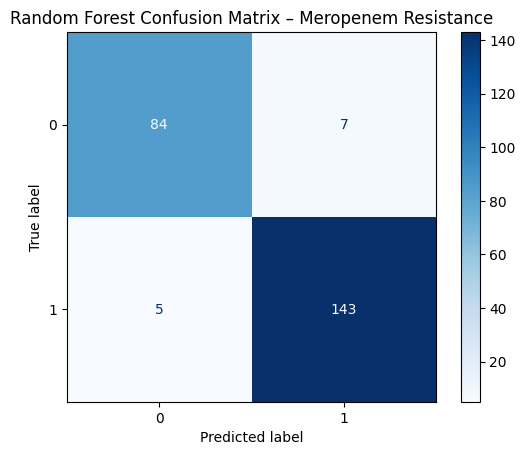

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('Random Forest Confusion Matrix – Meropenem Resistance')
plt.show()


**3. Gene Co-occurrence Network (Bonus visualization)**

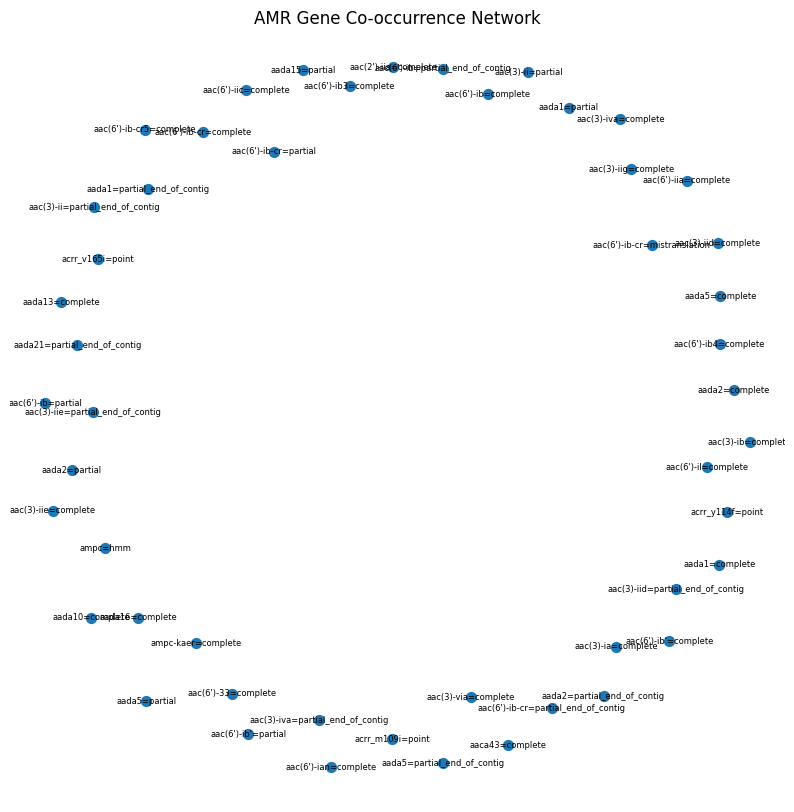

In [60]:
import networkx as nx
from itertools import combinations

# Build co-occurrence network (top genes)
top_genes = X_genes.columns[:50]
co_occurrence = pd.DataFrame(0, index=top_genes, columns=top_genes)

for genes in df['AMR_genotypes']:
    present = [g for g in top_genes if g in genes]
    for g1, g2 in combinations(present, 2):
        co_occurrence.loc[g1, g2] += 1
        co_occurrence.loc[g2, g1] += 1

G = nx.from_pandas_adjacency(co_occurrence)
plt.figure(figsize=(10,10))
nx.draw_networkx(G, node_size=50, font_size=6)
plt.title('AMR Gene Co-occurrence Network')
plt.axis('off')
plt.show()


**5. Model Comparison (Quick Benchmark)**

In [61]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=500)
log_reg.fit(X_train, y_train)
print("Logistic Regression F1:", 
      round(log_reg.score(X_test, y_test), 3))


Logistic Regression F1: 0.975


**6. Save and Document Everything**

In [64]:
df.to_csv('cleaned_kp_meropenem_dataset.csv', index=False)
pd.DataFrame({'Feature': top_feats.index, 'Importance': top_feats.values}).to_csv('top_features.csv', index=False)

**Step E1 — 5-Fold Cross-Validation**

In [65]:
from sklearn.model_selection import cross_val_score
import numpy as np

# 5-fold cross validation using F1-score (suitable for slightly imbalanced data)
scores = cross_val_score(model, X, y, cv=5, scoring='f1')

print("🔹 Cross-validation F1-scores:", np.round(scores, 3))
print("🔹 Mean F1:", round(np.mean(scores), 3))
print("🔹 Std Dev:", round(np.std(scores), 3))


🔹 Cross-validation F1-scores: [0.953 0.957 0.947 0.952 0.968]
🔹 Mean F1: 0.955
🔹 Std Dev: 0.007


**Step E2 — Confusion Matrix Visualization**

<Figure size 500x500 with 0 Axes>

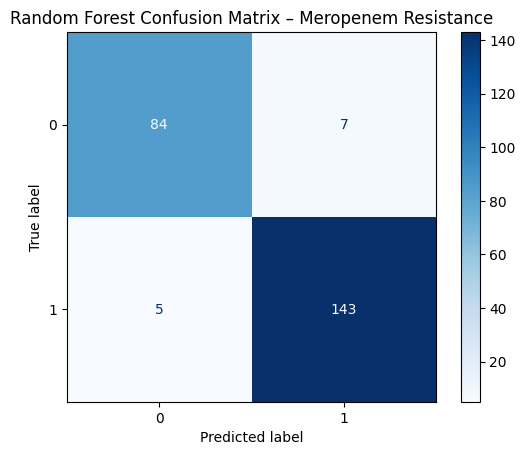

In [66]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(5,5))
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('Random Forest Confusion Matrix – Meropenem Resistance', fontsize=12)
plt.show()
